<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS08/JS08_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [9]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [10]:
id_cols = [c for c in df.columns if c.lower().replace(' ', '_') in ('sl_no', 'customer_key')]
features = df.drop(columns=id_cols)
print(features.columns.tolist())

from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(features)

['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


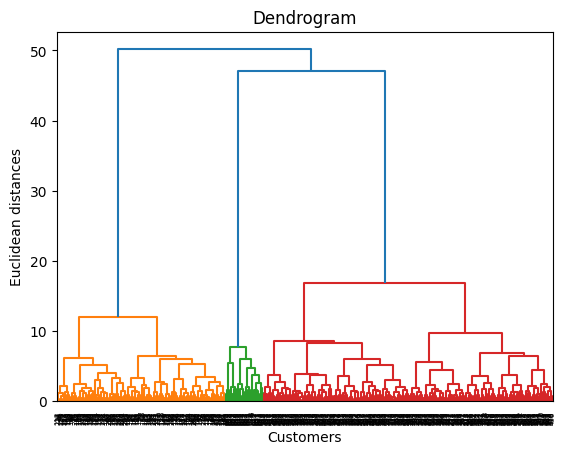

In [11]:
import scipy.cluster.hierarchy as sch

dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [12]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

print(np.unique(y_hc, return_counts=True))

(array([0, 1, 2]), array([385, 225,  50]))


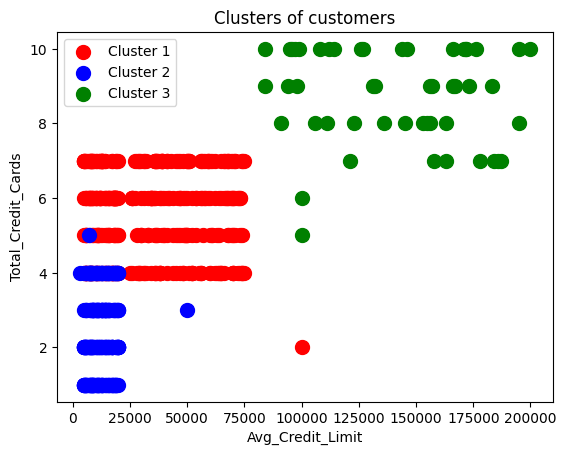

In [13]:
x_col = 'Avg_Credit_Limit'
y_col = 'Total_Credit_Cards'

colors = ['red', 'blue', 'green', 'cyan', 'magenta']
for k in np.unique(y_hc):
    plt.scatter(df.loc[y_hc == k, x_col],
                df.loc[y_hc == k, y_col],
                s=100, c=colors[k], label=f'Cluster {k + 1}')

plt.title('Clusters of customers')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.legend()
plt.show()

In [14]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sil_score = silhouette_score(X, y_hc)
dbi_score = davies_bouldin_score(X, y_hc)

print(f'Silhouette score: {sil_score}')
print(f'Davies-Bouldin Index: {dbi_score}')

Silhouette score: 0.5147639589977819
Davies-Bouldin Index: 0.680959518994733
